In [1]:
from pathlib import Path
import pickle
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import ParameterSampler

RANDOM_STATE = 42

DATA_DIR = Path(r"C:\DATA 4380\Tabular Project")
ARTIFACT_DIR = DATA_DIR / "model_artifacts"

TARGET = "correct"
CATEGORICAL_FEATURES = ["question_number"]

FINAL_THRESHOLD = 0.50

In [2]:
train_data = pd.read_pickle(ARTIFACT_DIR / "train_data.pkl")
val_data = pd.read_pickle(ARTIFACT_DIR / "val_data.pkl")
test_data = pd.read_pickle(ARTIFACT_DIR / "test_data.pkl")

with open(ARTIFACT_DIR / "event_count_columns.pkl", "rb") as file:
    event_count_columns = pickle.load(file)

BEHAVIORAL_FEATURES = list(event_count_columns)
FEATURES = CATEGORICAL_FEATURES + BEHAVIORAL_FEATURES

print("Training shape:", train_data.shape)
print("Validation shape:", val_data.shape)
print("Test shape:", test_data.shape)

print(f"\nNumber of features: {len(FEATURES)}")
print(FEATURES)

Training shape: (296856, 22)
Validation shape: (63630, 22)
Test shape: (63630, 22)

Number of features: 12
['question_number', 'event_count_checkpoint', 'event_count_cutscene_click', 'event_count_map_click', 'event_count_map_hover', 'event_count_navigate_click', 'event_count_notebook_click', 'event_count_notification_click', 'event_count_object_click', 'event_count_object_hover', 'event_count_observation_click', 'event_count_person_click']


In [3]:
def make_preprocessor():
    return ColumnTransformer(
        transformers = [
            (
                "categorical",
                OneHotEncoder(handle_unknown = "ignore"),
                CATEGORICAL_FEATURES,
            ),
            (
                "numeric",
                "passthrough",
                BEHAVIORAL_FEATURES,
            ),
        ],
        remainder = "drop",
    )


def make_lgbm_model(class_weight = None):
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", LGBMClassifier(
            objective = "binary",
            n_estimators = 300,
            learning_rate = 0.05,
            num_leaves = 31,
            class_weight = class_weight,
            random_state = RANDOM_STATE,
            verbosity = -1,
            n_jobs = -1,
        )),
    ])


def evaluate_predictions(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division = 0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division = 0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division = 0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "F1 (incorrect)": f1_score(
            y_true, y_pred, pos_label = 0, zero_division = 0
        ),
    }

In [4]:
required_columns = FEATURES + [TARGET, "base_session_id"]

for name, df in [
    ("train", train_data),
    ("validation", val_data),
    ("test", test_data),
]:
    missing = set(required_columns) - set(df.columns)

    if missing:
        raise ValueError(
            f"{name} data is missing columns: {missing}"
        )

    if df[TARGET].isna().any():
        raise ValueError(
            f"{name} data contains missing target values."
        )

    if df["base_session_id"].isna().any():
        raise ValueError(
            f"{name} data contains missing session IDs."
        )

    print(f"{name}: {len(df):,} rows | required columns verified")


train_sessions = set(train_data["base_session_id"].unique())
val_sessions = set(val_data["base_session_id"].unique())
test_sessions = set(test_data["base_session_id"].unique())

assert train_sessions.isdisjoint(val_sessions)
assert train_sessions.isdisjoint(test_sessions)
assert val_sessions.isdisjoint(test_sessions)

print("\nSession splits are disjoint.")

train: 296,856 rows | required columns verified
validation: 63,630 rows | required columns verified
test: 63,630 rows | required columns verified

Session splits are disjoint.


In [5]:
X_train = train_data[FEATURES].copy()
y_train = train_data[TARGET].copy()

X_val = val_data[FEATURES].copy()
y_val = val_data[TARGET].copy()

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

Training features: (296856, 12)
Validation features: (63630, 12)


In [6]:
class_distribution = pd.DataFrame({
    "Count": y_train.value_counts().sort_index(),
    "Proportion": y_train.value_counts(
        normalize=True
    ).sort_index(),
})

class_distribution.index = class_distribution.index.map({
    0: "Incorrect (0)",
    1: "Correct (1)",
})

display(class_distribution)

,Count,Proportion
correct,,
Incorrect (0),87071,0.293311
Correct (1),209785,0.706689


In [7]:
class_weight_options = {
    "Unweighted": None,
    "Balanced class weights": "balanced",
}

imbalance_models = {}
imbalance_predictions = {}
imbalance_results = []

for experiment_name, class_weight in class_weight_options.items():
    model = make_lgbm_model(class_weight = class_weight)
    model.fit(X_train, y_train)

    val_prob = model.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= FINAL_THRESHOLD).astype(int)

    imbalance_models[experiment_name] = model
    imbalance_predictions[experiment_name] = {
        "probabilities": val_prob,
        "predictions": val_pred,
    }

    metrics = evaluate_predictions(y_val, val_pred, val_prob)

    imbalance_results.append({
        "Experiment": experiment_name,
        **metrics,
    })


imbalance_results_df = (
    pd.DataFrame(imbalance_results)
    .sort_values("ROC-AUC", ascending = False)
    .reset_index(drop = True)
)

display(imbalance_results_df.round(4))

C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,F1 (incorrect)
0,Balanced class weights,0.6810,0.8441,0.6708,0.7475,0.7656,0.5668
1,Unweighted,0.7491,0.7664,0.9259,0.8386,0.7654,0.4368


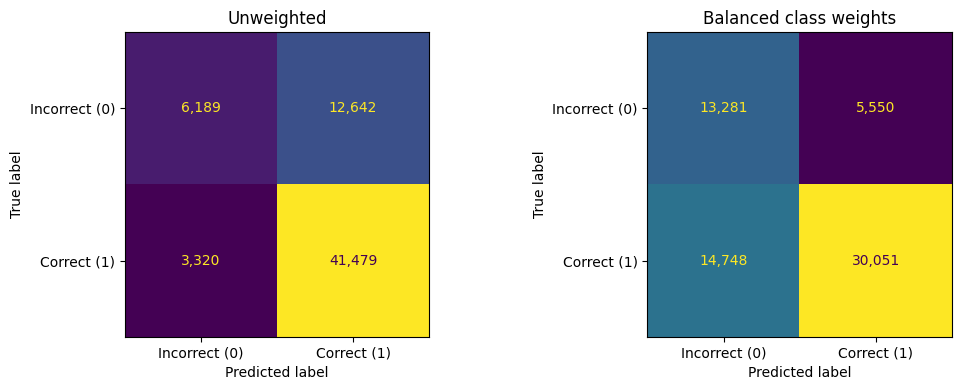

In [8]:
fig, axes = plt.subplots(1, 2, figsize = (11, 4))

for ax, experiment_name in zip(
    axes, class_weight_options.keys()
):
    val_pred = imbalance_predictions[experiment_name]["predictions"]

    cm = confusion_matrix(
        y_val, val_pred, labels = [0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix = cm,
        display_labels = ["Incorrect (0)", "Correct (1)"],
    ).plot(
        ax = ax,
        values_format = ",",
        colorbar = False,
    )

    ax.set_title(experiment_name)

plt.tight_layout()
plt.show()

In [9]:
unweighted_prob = imbalance_predictions["Unweighted"]["probabilities"]

thresholds = np.round(np.arange(0.30, 0.901, 0.025), 3)

threshold_results = []

for threshold in thresholds:
    val_pred = (unweighted_prob >= threshold).astype(int)

    metrics = evaluate_predictions(
        y_val, val_pred, unweighted_prob
    )

    threshold_results.append({
        "Threshold": threshold,
        **metrics,
    })


threshold_results_df = pd.DataFrame(threshold_results)

display(
    threshold_results_df[
        [
            "Threshold",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "F1 (incorrect)",
        ]
    ].round(4)
)

,Threshold,Accuracy,Precision,Recall,F1,F1 (incorrect)
0,0.300,0.7309,0.7282,0.9857,0.8376,0.2155
1,0.325,0.7340,0.7317,0.9823,0.8387,0.2416
2,0.350,0.7365,0.7354,0.9774,0.8393,0.2686
3,0.375,0.7403,0.7404,0.9720,0.8405,0.3012
4,0.400,0.7433,0.7451,0.9656,0.8412,0.3307
5,0.425,0.7455,0.7502,0.9574,0.8412,0.3596
6,0.450,0.7469,0.7551,0.9479,0.8406,0.3859
7,0.475,0.7484,0.7605,0.9381,0.8400,0.4113
8,0.500,0.7491,0.7664,0.9259,0.8386,0.4368
9,0.525,0.7479,0.7722,0.9105,0.8357,0.4588


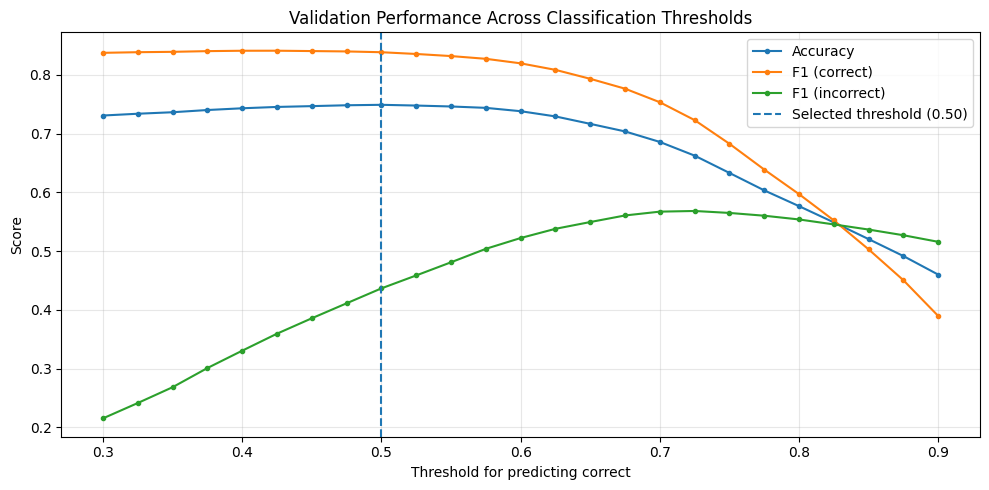

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_results_df["Threshold"],
    threshold_results_df["Accuracy"],
    marker="o",
    markersize=3,
    label="Accuracy",
)

plt.plot(
    threshold_results_df["Threshold"],
    threshold_results_df["F1"],
    marker="o",
    markersize=3,
    label="F1 (correct)",
)

plt.plot(
    threshold_results_df["Threshold"],
    threshold_results_df["F1 (incorrect)"],
    marker="o",
    markersize=3,
    label="F1 (incorrect)",
)

plt.axvline(
    FINAL_THRESHOLD,
    linestyle="--",
    label="Selected threshold (0.50)",
)

plt.xlabel("Threshold for predicting correct")
plt.ylabel("Score")
plt.title("Validation Performance Across Classification Thresholds")
plt.xticks(np.arange(0.30, 0.901, 0.10))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
baseline_model = imbalance_models["Unweighted"]

baseline_prob = imbalance_predictions["Unweighted"]["probabilities"]
baseline_pred = imbalance_predictions["Unweighted"]["predictions"]

baseline_metrics = evaluate_predictions(
    y_val, baseline_pred, baseline_prob
)

baseline_results_df = pd.DataFrame([{
    "Model": "Baseline LightGBM",
    "Threshold": FINAL_THRESHOLD,
    **baseline_metrics,
}])

display(baseline_results_df.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,F1 (incorrect)
0,Baseline LightGBM,0.5,0.7491,0.7664,0.9259,0.8386,0.7654,0.4368


In [12]:
PARAMETER_SPACE = {
    "n_estimators": [200, 300, 500, 700],
    "learning_rate": [0.02, 0.03, 0.05, 0.08, 0.10],
    "num_leaves": [15, 31, 47, 63],
    "max_depth": [-1, 5, 7, 10],
    "min_child_samples": [20, 50, 100, 200],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "reg_lambda": [0.0, 0.1, 1.0, 5.0, 10.0],
}

N_ITER = 20

parameter_candidates = list(
    ParameterSampler(
        PARAMETER_SPACE,
        n_iter = N_ITER,
        random_state = RANDOM_STATE,
    )
)

print(
    f"Number of candidate configurations: "
    f"{len(parameter_candidates)}"
)

Number of candidate configurations: 20


In [13]:
tuning_results = []

best_tuned_model = None
best_tuned_params = None
best_tuned_auc = -np.inf

for i, params in enumerate(parameter_candidates, start = 1):
    model = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", LGBMClassifier(
            objective = "binary",
            class_weight = None,
            random_state = RANDOM_STATE,
            verbosity = -1,
            n_jobs = -1,
            subsample_freq = 1,
            **params,
        )),
    ])

    model.fit(X_train, y_train)

    val_prob = model.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= FINAL_THRESHOLD).astype(int)

    metrics = evaluate_predictions(
        y_val, val_pred, val_prob
    )

    tuning_results.append({
        "Candidate": i,
        **params,
        **metrics,
    })

    if metrics["ROC-AUC"] > best_tuned_auc:
        best_tuned_auc = metrics["ROC-AUC"]
        best_tuned_params = params.copy()
        best_tuned_model = model

    print(
        f"Candidate {i:02d}/{N_ITER} | "
        f"ROC-AUC: {metrics['ROC-AUC']:.5f} | "
        f"Best so far: {best_tuned_auc:.5f}"
    )

tuning_results_df = pd.DataFrame(tuning_results)

C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Candidate 01/20 | ROC-AUC: 0.76575 | Best so far: 0.76575


C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Candidate 02/20 | ROC-AUC: 0.76317 | Best so far: 0.76575


C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


...

C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Candidate 18/20 | ROC-AUC: 0.76588 | Best so far: 0.76633


C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Candidate 19/20 | ROC-AUC: 0.76508 | Best so far: 0.76633
Candidate 20/20 | ROC-AUC: 0.76331 | Best so far: 0.76633


C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [14]:
tuning_leaderboard = (
    tuning_results_df
    .sort_values("ROC-AUC", ascending = False)
    .reset_index(drop = True)
)

leaderboard_columns = [
    "Candidate",
    "n_estimators",
    "learning_rate",
    "num_leaves",
    "max_depth",
    "min_child_samples",
    "subsample",
    "colsample_bytree",
    "reg_lambda",
    "Accuracy",
    "F1",
    "F1 (incorrect)",
    "ROC-AUC",
]

display(
    tuning_leaderboard[leaderboard_columns].round(4)
)

print("\nBest hyperparameters:")
print(best_tuned_params)

print(f"\nBest validation ROC-AUC: {best_tuned_auc:.5f}")

,Candidate,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_lambda,Accuracy,F1,F1 (incorrect),ROC-AUC
0,14,700,0.03,47,5,200,0.85,1.00,0.0,0.7490,0.8387,0.4351,0.7663
1,3,500,0.02,31,-1,200,1.00,0.70,0.1,0.7490,0.8388,0.4331,0.7660
2,13,500,0.05,47,5,20,0.85,1.00,0.0,0.7490,0.8386,0.4359,0.7659
3,18,200,0.02,63,-1,200,0.85,0.70,0.1,0.7493,0.8399,0.4221,0.7659
4,1,200,0.10,31,7,200,0.85,1.00,1.0,0.7489,0.8384,0.4377,0.7657
5,10,200,0.10,63,5,100,1.00,0.70,0.1,0.7494,0.8392,0.4327,0.7655
6,6,300,0.03,47,7,100,1.00,1.00,0.0,0.7491,0.8389,0.4332,0.7654
7,15,700,0.10,15,-1,100,0.70,0.70,0.1,0.7487,0.8380,0.4403,0.7654
8,19,700,0.10,15,7,50,0.85,1.00,0.0,0.7480,0.8373,0.4418,0.7651
9,7,200,0.05,15,10,200,0.85,0.70,0.1,0.7495,0.8390,0.4363,0.7650



Best hyperparameters:
{'subsample': 0.85, 'reg_lambda': 0.0, 'num_leaves': 47, 'n_estimators': 700, 'min_child_samples': 200, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 1.0}

Best validation ROC-AUC: 0.76633


In [15]:
best_tuned_prob = best_tuned_model.predict_proba(X_val)[:, 1]
best_tuned_pred = (
    best_tuned_prob >= FINAL_THRESHOLD
).astype(int)

tuned_metrics = evaluate_predictions(
    y_val, best_tuned_pred, best_tuned_prob
)

baseline_vs_tuned_df = pd.DataFrame([
    {
        "Model": "Baseline LightGBM",
        "Threshold": FINAL_THRESHOLD,
        **baseline_metrics,
    },
    {
        "Model": "Tuned LightGBM",
        "Threshold": FINAL_THRESHOLD,
        **tuned_metrics,
    },
]).sort_values(
    "ROC-AUC", ascending = False
).reset_index(drop = True)

display(baseline_vs_tuned_df.round(4))

C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,F1 (incorrect)
0,Tuned LightGBM,0.5,0.7490,0.7660,0.9266,0.8387,0.7663,0.4351
1,Baseline LightGBM,0.5,0.7491,0.7664,0.9259,0.8386,0.7654,0.4368


In [16]:
final_model = best_tuned_model
final_threshold = FINAL_THRESHOLD

print("Selected model: Tuned LightGBM")
print("Selected threshold:", final_threshold)
print(f"Validation ROC-AUC: {best_tuned_auc:.5f}")

Selected model: Tuned LightGBM
Selected threshold: 0.5
Validation ROC-AUC: 0.76633


In [17]:
X_test = test_data[FEATURES].copy()
y_test = test_data[TARGET].copy()

test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= final_threshold).astype(int)

test_metrics = evaluate_predictions(
    y_test, test_pred, test_prob
)

test_results_df = pd.DataFrame([{
    "Model": "Tuned LightGBM",
    "Threshold": final_threshold,
    **test_metrics,
}])

display(test_results_df.round(4))

C:\Users\Tim Garen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,F1 (incorrect)
0,Tuned LightGBM,0.5,0.7516,0.7667,0.929,0.8401,0.7726,0.4438


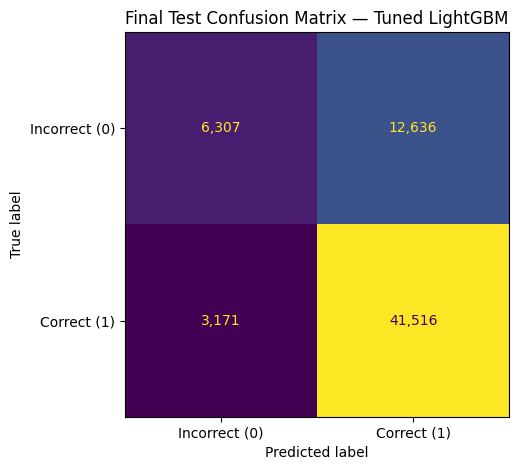

In [18]:
ConfusionMatrixDisplay(
    confusion_matrix = confusion_matrix(
        y_test,
        test_pred,
        labels = [0, 1],
    ),
    display_labels = ["Incorrect (0)", "Correct (1)"],
).plot(values_format = ",", colorbar = False)

plt.title("Final Test Confusion Matrix — Tuned LightGBM")
plt.tight_layout()
plt.show()

In [19]:
final_comparison_df = pd.DataFrame([
    {
        "Split": "Validation",
        **tuned_metrics,
    },
    {
        "Split": "Test",
        **test_metrics,
    },
])

display(final_comparison_df.round(4))

,Split,Accuracy,Precision,Recall,F1,ROC-AUC,F1 (incorrect)
0,Validation,0.7490,0.7660,0.9266,0.8387,0.7663,0.4351
1,Test,0.7516,0.7667,0.9290,0.8401,0.7726,0.4438


In [20]:
fitted_preprocessor = final_model.named_steps["preprocessor"]
fitted_classifier = final_model.named_steps["classifier"]

transformed_feature_names = (
    fitted_preprocessor.get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": fitted_classifier.booster_.feature_importance(
        importance_type = "gain"
    ),
})

importance_df = (
    importance_df
    .sort_values("Importance", ascending = False)
    .reset_index(drop = True)
)

display(importance_df.head(15).round(3))

,Feature,Importance
0,categorical__question_number_13,198351.107
1,categorical__question_number_18,106903.066
2,numeric__event_count_object_click,93593.148
3,numeric__event_count_map_click,78396.134
4,numeric__event_count_navigate_click,69891.862
5,categorical__question_number_2,68590.059
6,categorical__question_number_15,48062.471
7,categorical__question_number_10,39125.133
8,categorical__question_number_12,37371.235
9,categorical__question_number_3,37259.844


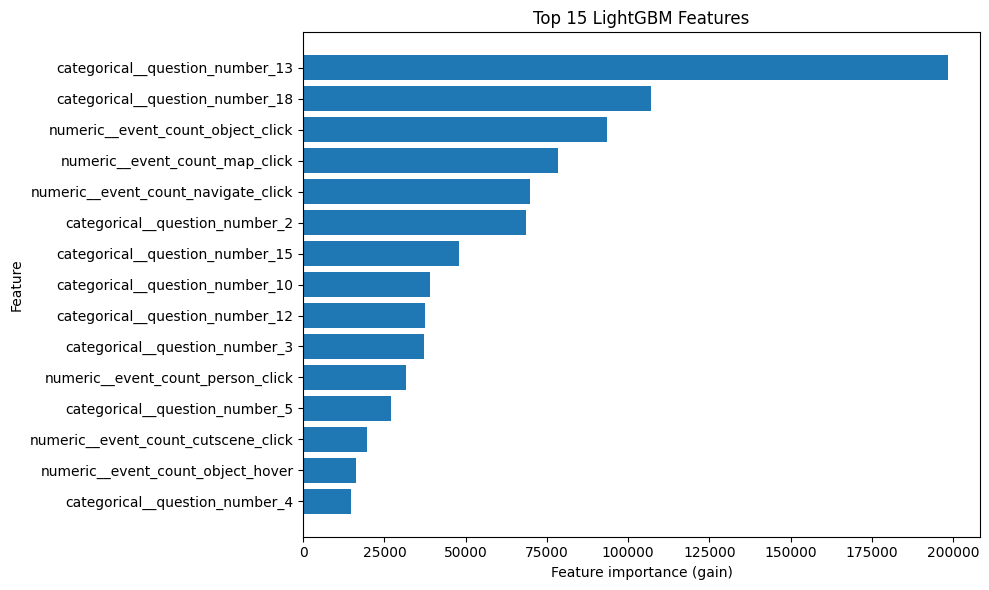

In [21]:
top_features = (
    importance_df
    .head(15)
    .sort_values("Importance")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
)

plt.xlabel("Feature importance (gain)")
plt.ylabel("Feature")
plt.title("Top 15 LightGBM Features")
plt.tight_layout()
plt.show()

In [22]:
MODEL_DIR = ARTIFACT_DIR / "final_model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    final_model,
    MODEL_DIR / "lightgbm_final.joblib",
)

final_config = {
    "model": "LightGBM",
    "feature_set": "Original",
    "threshold": float(final_threshold),
    "primary_metric": "ROC-AUC",
    "random_state": RANDOM_STATE,
    "best_validation_roc_auc": float(best_tuned_auc),
    "hyperparameters": best_tuned_params,
}

with open(MODEL_DIR / "final_config.json", "w") as file:
    json.dump(final_config, file, indent=4)

test_results_df.to_csv(
    MODEL_DIR / "test_metrics.csv",
    index=False,
)

importance_df.to_csv(
    MODEL_DIR / "feature_importance.csv",
    index=False,
)

baseline_vs_tuned_df.to_csv(
    MODEL_DIR / "validation_model_comparison.csv",
    index=False,
)

final_comparison_df.to_csv(
    MODEL_DIR / "validation_test_comparison.csv",
    index=False,
)

print("Final artifacts saved to:", MODEL_DIR)

Final artifacts saved to: C:\DATA 4380\Tabular Project\model_artifacts\final_model
